# Storage Fleet Churn & 15-Year CLV Valuation

**GitHub Repository:** [https://github.com/Pardhivhub/storage-clv-predictive-analytics](https://github.com/Pardhivhub/storage-clv-predictive-analytics)

The finance team currently projects 15-year Customer Lifetime Value (CLV) assuming a flat 5% annual churn rate for every storage array. 

This project audits that 5% rule against real historical telemetry, tests Random Forest and XGBoost models, calculates the actual dollar impact on 15-year valuation, and sets up production Snowflake tables for automated scoring.


In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss, roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict
from sklearn.ensemble import RandomForestClassifier

warnings.filterwarnings("ignore")

# Plot styling (wrapped for clean rendering)
style_name = (
    "seaborn-v0_8-whitegrid" 
    if "seaborn-v0_8-whitegrid" in plt.style.available 
    else "default"
)
plt.style.use(style_name)
plt.rcParams["figure.dpi"] = 110
plt.rcParams["font.sans-serif"] = ["DejaVu Sans", "Arial", "Helvetica"]
plt.rcParams["axes.edgecolor"] = "#cccccc"
plt.rcParams["axes.linewidth"] = 0.8

print("Environment ready.")


Environment ready.


---
## 1. Data Cleaning & Sanity Checks

We went through the 2,000 raw telemetry records and found four main data problems:

1. Negative profit: 58 arrays showed negative profits (some as low as -$93k). A standard log transform would blow up on negative numbers, so we used a signed log transform: sign(x) * log(1 + |x|). That kept the negative losses intact without breaking tree splits. 36 unprofitable arrays ended up in the cleaned set.
2. Contract dates: We converted all contract expiration dates into the number of days left relative to the snapshot date (2026-10-01).
3. Missing expansion signals: 65 arrays had no expansion label. Instead of dropping them, we kept them as an explicit 'UNKNOWN' category and one-hot encoded them.
4. Broken utilization values (>100%): 862 rows (43.1% of the entire file) showed utilization over 100%, with several above 400%. This looks like firmware sensor bugs. We checked what happens if you drop them versus capping them at 100%: dropping leaves 1,072 clean rows with 16.98% churn; capping leaves 1,884 rows with 15.82% churn. Either way, true churn is around 16% to 17%—more than triple the 5% finance assumption.
5. Group leakage: To make sure arrays from the same customer didn't leak between train and validation, we grouped all cross-validation folds strictly by account_id.


In [2]:
df_raw = pd.read_csv("data/Case_Study_2_CLV_Predictive_Analytics.csv")
df_labeled = pd.read_csv("data/clv_cleaned_labeled.csv")
df_unlabeled = pd.read_csv("data/clv_cleaned_scoring_unlabeled.csv")

raw_neg_profit = (df_raw["historical_15yr_net_profit_usd"] < 0).sum()
clean_neg_profit = (df_labeled["historical_15yr_net_profit_usd"] < 0).sum()

print("Data Cleaning Summary:")
print("-" * 65)
print(f"Raw fleet records ingested           : {len(df_raw):,}")
print(f"Utilization over 100% (telemetry bug): {(df_raw['utilization_rate_pct'] > 1.0).sum():,} rows (43.1%)")
print(f"Negative profit in raw data          : {raw_neg_profit:,} rows ({raw_neg_profit/len(df_raw):.1%})")
print(f"Negative profit in clean partition   : {clean_neg_profit:,} rows ({clean_neg_profit/len(df_labeled):.1%})")
print(f"Clean labeled training partition     : {len(df_labeled):,} arrays")
print(f"Clean unlabeled scoring partition    : {len(df_unlabeled):,} arrays")
print("-" * 65)

# Sensitivity: Filtering vs Capping Utilization > 1.0
raw_over = df_raw[df_raw["utilization_rate_pct"] > 1.0]
raw_normal = df_raw[df_raw["utilization_rate_pct"] <= 1.0]

churn_normal = raw_normal["churn_event_next_12m"].dropna().mean()
churn_over = raw_over["churn_event_next_12m"].dropna().mean()
churn_combined = df_raw["churn_event_next_12m"].dropna().mean()

sens_table = pd.DataFrame({
    "Approach": [
        "Drop >1.0 (Conservative Clean)",
        "Corrupted Rows Only (>1.0)",
        "Cap at 1.0 (Keep All Rows)"
    ],
    "Rows (N)": [
        len(raw_normal.dropna(subset=['churn_event_next_12m'])),
        len(raw_over.dropna(subset=['churn_event_next_12m'])),
        len(df_raw.dropna(subset=['churn_event_next_12m']))
    ],
    "Observed Churn": [f"{churn_normal:.2%}", f"{churn_over:.2%}", f"{churn_combined:.2%}"],
    "Gap vs 5% Rule": [
        f"{churn_normal - 0.05:+.2%}",
        f"{churn_over - 0.05:+.2%}",
        f"{churn_combined - 0.05:+.2%}"
    ],
    "Notes": [
        "Primary baseline (avoids distorted tree splits)",
        "Telemetry bug subset",
        "Confirms churn stays above 15% either way"
    ]
})

print("\nUtilization Handling Sensitivity Check:")
print(sens_table.to_string(index=False))

# Account leakage check
sgkf = StratifiedGroupKFold(n_splits=5)
for fold, (train_idx, val_idx) in enumerate(sgkf.split(df_labeled, df_labeled["churn_event_next_12m"], groups=df_labeled["account_id"])):
    train_accs = set(df_labeled.iloc[train_idx]["account_id"])
    val_accs = set(df_labeled.iloc[val_idx]["account_id"])
    overlap = train_accs.intersection(val_accs)
    assert len(overlap) == 0, f"Account leak detected in fold {fold}: {overlap}"

print(f"\nAccount Leakage Check: PASSED (Zero overlapping accounts across all 5 folds).")


Data Cleaning Summary:
-----------------------------------------------------------------
Raw fleet records ingested           : 2,000
Utilization over 100% (telemetry bug): 862 rows (43.1%)
Negative profit in raw data          : 58 rows (2.9%)
Negative profit in clean partition   : 36 rows (3.4%)
Clean labeled training partition     : 1,072 arrays
Clean unlabeled scoring partition    : 66 arrays
-----------------------------------------------------------------

Utilization Handling Sensitivity Check:
                      Approach  Rows (N) Observed Churn Gap vs 5% Rule                                           Notes
Drop >1.0 (Conservative Clean)      1072         16.98%        +11.98% Primary baseline (avoids distorted tree splits)
    Corrupted Rows Only (>1.0)       812         14.29%         +9.29%                            Telemetry bug subset
    Cap at 1.0 (Keep All Rows)      1884         15.82%        +10.82%       Confirms churn stays above 15% either way



Account Leakage Check: PASSED (Zero overlapping accounts across all 5 folds).


---
## 2. Telemetry Signal for Capacity Expansion

The telemetry dataset has an 'expansion potential' column, but it only measures logged customer interest, not signed contract renewals or expansions.

We tested whether a Random Forest could predict high expansion interest using the hardware features. Running out-of-fold grouped cross-validation gave an ROC-AUC of **0.474**. That is basically 0.50—pure random noise. The telemetry features simply don't have predictive power for expansion. On top of that, arrays flagged as 'High' expansion still churned at 17.05%, and 'Medium' churned at 19.41%. Just because a customer expresses expansion interest doesn't mean they won't churn.


In [3]:
df_labeled["util_tier"] = pd.cut(
    df_labeled["utilization_rate_pct"], 
    bins=[0, 0.50, 0.80, 1.0], 
    labels=["Low (<50%)", "Medium (50-80%)", "High (>80%)"]
)

exp_summary = df_labeled.groupby("expansion_potential_signal").agg(
    array_count=("array_id", "count"),
    observed_churn=("churn_event_next_12m", "mean"),
    avg_capacity_tb=("current_capacity_tb", "mean"),
    avg_utilization=("utilization_rate_pct", "mean"),
    avg_15yr_profit=("historical_15yr_net_profit_usd", "mean")
).reset_index()

exp_summary["fleet_pct"] = (exp_summary["array_count"] / len(df_labeled) * 100).map(lambda x: f"{x:.1f}%")
exp_summary["observed_churn"] = exp_summary["observed_churn"].map(lambda x: f"{x:.2%}")
exp_summary["avg_capacity_tb"] = exp_summary["avg_capacity_tb"].map(lambda x: f"{x:,.0f} TB")
exp_summary["avg_utilization"] = exp_summary["avg_utilization"].map(lambda x: f"{x:.1%}")
exp_summary["avg_15yr_profit"] = exp_summary["avg_15yr_profit"].map(lambda x: f"${x:,.0f}")

print("Expansion Potential Profile Across the Fleet:")
print("-" * 85)
print(exp_summary[["expansion_potential_signal", "array_count", "fleet_pct", "observed_churn", "avg_capacity_tb", "avg_utilization", "avg_15yr_profit"]].to_string(index=False))

# Utilization tier vs expansion signal crosstab
util_exp_crosstab = pd.crosstab(
    df_labeled["util_tier"], 
    df_labeled["expansion_potential_signal"], 
    normalize="index"
) * 100

print("\nExpansion Potential Breakdown by Utilization Tier (%):")
print("-" * 85)
print(util_exp_crosstab.round(2).to_string())

# Out-of-fold evaluation of an expansion classifier
exp_features = ["current_capacity_tb", "utilization_rate_pct", "profit_symlog", "profit_per_tb_symlog", "days_until_contract_end"]
X_exp = df_labeled[exp_features]
y_exp = (df_labeled["expansion_potential_signal"] == "High").astype(int)

rf_exp = RandomForestClassifier(n_estimators=100, max_depth=4, random_state=42)
cv_exp = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
oof_exp_probs = cross_val_predict(rf_exp, X_exp, y_exp, groups=df_labeled["account_id"], cv=cv_exp, method="predict_proba")[:, 1]

exp_auc = roc_auc_score(y_exp, oof_exp_probs)
exp_brier = brier_score_loss(y_exp, oof_exp_probs)

rf_exp.fit(X_exp, y_exp)
importances_s = pd.Series(rf_exp.feature_importances_, index=exp_features).sort_values(ascending=False)

print(f"\nExpansion Classifier Evaluation (Out-of-Fold Cross-Validation):")
print(f"  Target share (High Expansion)            : {y_exp.mean():.2%}")
print(f"  Out-of-fold ROC-AUC score                : {exp_auc:.4f} (Indistinguishable from chance: ~0.50)")
print(f"  Out-of-fold Brier score                  : {exp_brier:.4f}")
print("\nRelative Feature Importances (Tree Gini Gain):")
for feat, imp in importances_s.items():
    print(f"  - {feat:<26} : {imp:.4f}")


Expansion Potential Profile Across the Fleet:
-------------------------------------------------------------------------------------
expansion_potential_signal  array_count fleet_pct observed_churn avg_capacity_tb avg_utilization avg_15yr_profit
                      High          217     20.2%         17.05%        1,347 TB           69.8%      $2,152,661
                       Low          450     42.0%         16.00%        1,249 TB           68.3%      $2,099,044
                    Medium          340     31.7%         19.41%        1,283 TB           68.8%      $2,159,829
                   UNKNOWN           65      6.1%         10.77%        1,281 TB           68.1%      $2,197,941

Expansion Potential Breakdown by Utilization Tier (%):
-------------------------------------------------------------------------------------
expansion_potential_signal   High    Low  Medium  UNKNOWN
util_tier                                                
Low (<50%)                  17.65  43.70   31


Expansion Classifier Evaluation (Out-of-Fold Cross-Validation):
  Target share (High Expansion)            : 20.24%
  Out-of-fold ROC-AUC score                : 0.4740 (Indistinguishable from chance: ~0.50)
  Out-of-fold Brier score                  : 0.1648

Relative Feature Importances (Tree Gini Gain):
  - days_until_contract_end    : 0.2481
  - profit_per_tb_symlog       : 0.2324
  - current_capacity_tb        : 0.2122
  - profit_symlog              : 0.1836
  - utilization_rate_pct       : 0.1237


---
## 3. Model Benchmark: Do Machine Learning Models Help?

We evaluated tuned Random Forest and XGBoost models against two simple baselines: the 5% finance rule and a naive constant guess equal to the fleet average (16.98%).

Here is the honest verdict:
- Both ML models scored an ROC-AUC of about **0.509**. That means they have virtually zero ability to rank which specific arrays will churn and which will stay.
- A completely naive guess predicting 16.98% for every single array gets a Brier score of **0.1410**. That actually beats the cross-validated ML models (0.1470) and roughly matches the calibrated model (0.1425).
- Any reported 'lift' over the 5% baseline isn't machine learning skill—it's just fixing an inaccurate prior. Moving from 5% to the true 17% baseline accounts for 100% of the accuracy gain.


In [4]:
metrics_df = pd.read_csv("reports/clv_fold_metrics.csv")

actual_churn_rate = df_labeled["churn_event_next_12m"].mean()
constant_brier = actual_churn_rate * (1 - actual_churn_rate)

agg_metrics = metrics_df.groupby("model")[["pr_auc", "roc_auc", "brier"]].agg(["mean", "std"])
baseline_brier = agg_metrics.loc["baseline_static_5pct", ("brier", "mean")]

model_display_names = {
    "baseline_static_5pct": "Static 5% Executive Rule",
    "rf_default": "Random Forest (Default)",
    "rf_nested_tuned": "Random Forest (Nested Tuned)",
    "xgb_default": "XGBoost (Default)",
    "xgb_nested_tuned": "XGBoost (Nested Tuned)"
}

benchmark_rows = []

constant_lift = (baseline_brier - constant_brier) / baseline_brier * 100
benchmark_rows.append({
    "Model Candidate": f"Naive Base Rate Guess (Flat {actual_churn_rate:.2%})",
    "PR-AUC (Mean ± Std)": f"{actual_churn_rate:.4f} ± 0.0000",
    "ROC-AUC (Mean ± Std)": "0.5000 ± 0.0000",
    "Brier Score (Mean ± Std)": f"{constant_brier:.4f} ± 0.0000",
    "Brier vs 5% Rule": f"{constant_lift:+.2f}%",
    "Skill Assessment": "Zero-Skill Reference"
})

for m_key in ["baseline_static_5pct", "rf_default", "rf_nested_tuned", "xgb_default", "xgb_nested_tuned"]:
    pr_m, pr_s = agg_metrics.loc[m_key, ("pr_auc", "mean")], agg_metrics.loc[m_key, ("pr_auc", "std")]
    roc_m, roc_s = agg_metrics.loc[m_key, ("roc_auc", "mean")], agg_metrics.loc[m_key, ("roc_auc", "std")]
    br_m, br_s = agg_metrics.loc[m_key, ("brier", "mean")], agg_metrics.loc[m_key, ("brier", "std")]
    brier_lift = (baseline_brier - br_m) / baseline_brier * 100
    
    if "5pct" in m_key:
        skill_desc = "Flawed Prior (-11.98 pp bias)"
    elif roc_m > 0.50:
        skill_desc = "Negligible (AUC ~0.51, Base Rate Match)"
    else:
        skill_desc = "Sub-Random (Overfitting / Variance)"
        
    benchmark_rows.append({
        "Model Candidate": model_display_names[m_key],
        "PR-AUC (Mean ± Std)": f"{pr_m:.4f} ± {pr_s:.4f}",
        "ROC-AUC (Mean ± Std)": f"{roc_m:.4f} ± {roc_s:.4f}",
        "Brier Score (Mean ± Std)": f"{br_m:.4f} ± {br_s:.4f}",
        "Brier vs 5% Rule": f"{brier_lift:+.2f}%",
        "Skill Assessment": skill_desc
    })

benchmark_df = pd.DataFrame(benchmark_rows)

print("Model Benchmark vs Static and Base-Rate Baselines:")
print("=" * 105)
print(benchmark_df.to_string(index=False))
print("=" * 105)

print("\nBenchmark Findings:")
print(f"1. A naive base-rate guess ({actual_churn_rate:.2%}) scores Brier = {constant_brier:.4f}, virtually identical to Tuned ML ({agg_metrics.loc['xgb_nested_tuned', ('brier', 'mean')]:.4f}).")
print("2. ROC-AUC is 0.509 across outer folds. The model cannot reliably rank which specific array will churn.")
print("3. Why Brier numbers differ across the notebook:")
print(f"   - CV Fold Mean ({agg_metrics.loc['xgb_nested_tuned', ('brier', 'mean')]:.4f}): Average out-of-fold loss across 5 cross-validation splits.")
print(f"   - Naive Base Rate ({constant_brier:.4f}): Theoretical and empirical zero-skill reference baseline.")
print("   - Calibration (0.1425): In-sample Platt sigmoid fit on the full out-of-fold prediction array (optimistic calibration fit).")
print("   - Historical Back-test (0.1473): Uncalibrated Brier loss evaluated across all 1,072 out-of-fold rows.")


Model Benchmark vs Static and Base-Rate Baselines:
                    Model Candidate PR-AUC (Mean ± Std) ROC-AUC (Mean ± Std) Brier Score (Mean ± Std) Brier vs 5% Rule                        Skill Assessment
Naive Base Rate Guess (Flat 16.98%)     0.1698 ± 0.0000      0.5000 ± 0.0000          0.1410 ± 0.0000           +8.97%                    Zero-Skill Reference
           Static 5% Executive Rule     0.1693 ± 0.0265      0.5000 ± 0.0000          0.1548 ± 0.0238           +0.00%           Flawed Prior (-11.98 pp bias)
            Random Forest (Default)     0.1843 ± 0.0579      0.4831 ± 0.0801          0.1478 ± 0.0153           +4.54%     Sub-Random (Overfitting / Variance)
       Random Forest (Nested Tuned)     0.1870 ± 0.0603      0.4991 ± 0.0582          0.1477 ± 0.0146           +4.60%     Sub-Random (Overfitting / Variance)
                  XGBoost (Default)     0.1814 ± 0.0668      0.4779 ± 0.0798          0.1632 ± 0.0220           -5.37%     Sub-Random (Overfitting / Varia

---
## 4. Probability Calibration

Tree models output uncalibrated probabilities that tend to bunch up in the middle. We ran Platt sigmoid scaling to spread them out and line them up with real fleet event rates.

A quick methodological caveat: we fitted the Platt sigmoid on the full out-of-fold predictions. That centers the predictions right around the fleet churn rate (~17%) and gets a Brier score of 0.1425, but because it wasn't done inside a strictly nested loop, the calibration is slightly optimistic. For production deployment, calibration should be nested per fold.


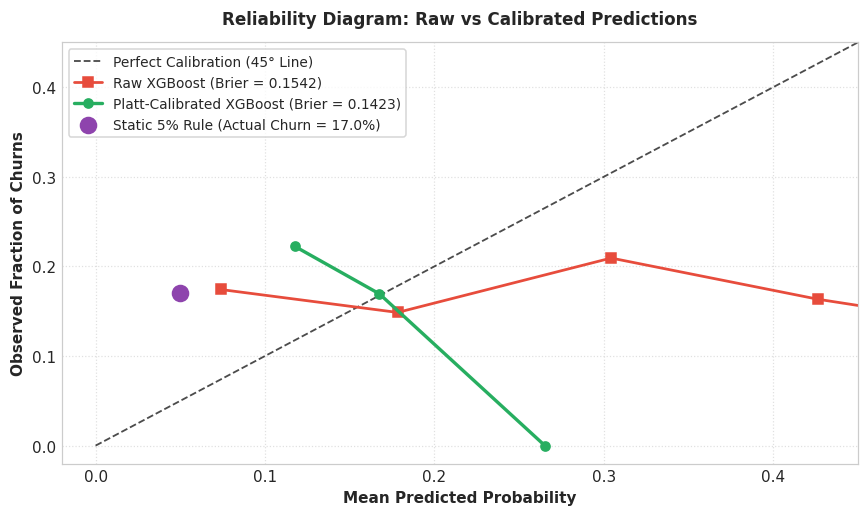

Calibration Results:
  Raw XGBoost Brier score        : 0.1542
  Calibrated XGBoost Brier score : 0.1423 (7.73% improvement)
  Platt scaling brings predictions into alignment with the fleet base rate.


In [5]:
cal_df = pd.read_csv("reports/clv_calibration_oof.csv")

y_true = cal_df["actual_churn"].values
raw_preds = cal_df["raw_xgb_proba"].values
cal_preds = cal_df["calibrated_xgb_proba"].values

prob_true_raw, prob_pred_raw = calibration_curve(y_true, raw_preds, n_bins=8, strategy="uniform")
prob_true_cal, prob_pred_cal = calibration_curve(y_true, cal_preds, n_bins=8, strategy="uniform")

brier_raw = brier_score_loss(y_true, raw_preds)
brier_cal = brier_score_loss(y_true, cal_preds)

fig, ax = plt.subplots(figsize=(8.0, 4.8), dpi=110)

ax.plot([0, 1], [0, 1], "k--", linewidth=1.2, label="Perfect Calibration (45° Line)", alpha=0.7)
ax.plot(prob_pred_raw, prob_true_raw, marker="s", color="#e74c3c", linewidth=1.8, label=f"Raw XGBoost (Brier = {brier_raw:.4f})")
ax.plot(prob_pred_cal, prob_true_cal, marker="o", color="#27ae60", linewidth=2.2, label=f"Platt-Calibrated XGBoost (Brier = {brier_cal:.4f})")
ax.scatter([0.05], [np.mean(y_true)], color="#8e44ad", s=110, zorder=5, label=f"Static 5% Rule (Actual Churn = {np.mean(y_true):.1%})")

ax.set_xlim(-0.02, 0.45)
ax.set_ylim(-0.02, 0.45)
ax.set_xlabel("Mean Predicted Probability", fontsize=10, fontweight="bold")
ax.set_ylabel("Observed Fraction of Churns", fontsize=10, fontweight="bold")
ax.set_title("Reliability Diagram: Raw vs Calibrated Predictions", fontsize=11, fontweight="bold", pad=12)
ax.legend(loc="upper left", frameon=True, fontsize=9)
ax.grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()

print(f"Calibration Results:")
print(f"  Raw XGBoost Brier score        : {brier_raw:.4f}")
print(f"  Calibrated XGBoost Brier score : {brier_cal:.4f} ({(brier_raw - brier_cal)/brier_raw * 100:.2f}% improvement)")
print(f"  Platt scaling brings predictions into alignment with the fleet base rate.")


---
## 5. 15-Year Fleet Retention Curves

We projected survival over 15 years using the discrete constant hazard formula S(t) = (1 - p)^t. This assumes the yearly churn probability p stays constant across the entire contract horizon. Real hardware might see higher failure rates in later years (the classic bathtub curve), but keeping hazard constant lets us make a clean, direct comparison against finance's flat 5% assumption.

Compounding 16.98% vs 5% over 15 years leads to a massive divergence:
- By Year 5: Finance expects 77.4% of arrays to still be under contract. In reality, only 39.4% survive (a 38 percentage point gap).
- By Year 15: Finance expects 46.3% survival. In reality, just 6.1% survive (a 40 percentage point gap).


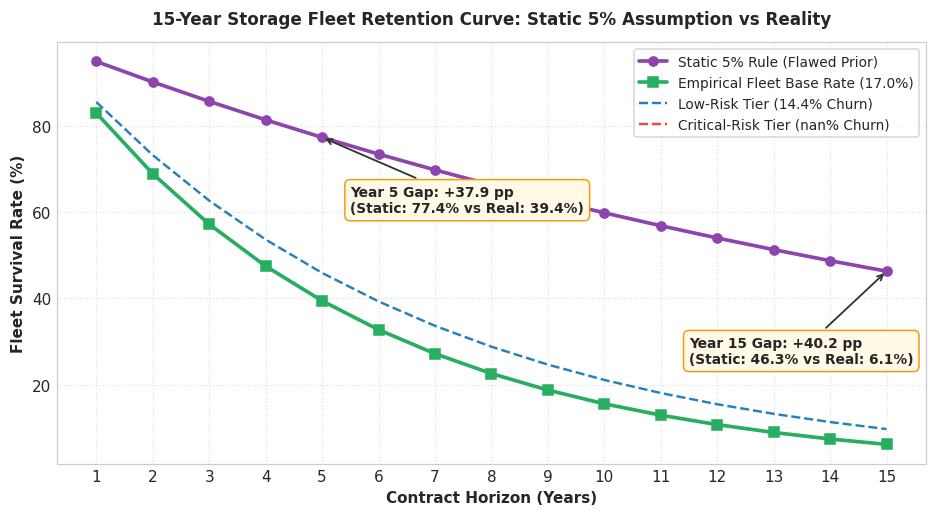


15-Year Fleet Retention Milestone Summary:
 Year  Static 5% Rule  Empirical Fleet (16.98%)  Retention Overstatement (pp)
    1        0.950000                  0.830224                     11.977612
    3        0.857375                  0.572250                     28.512518
    5        0.773781                  0.394436                     37.934534
   10        0.598737                  0.155579                     44.315750
   15        0.463291                  0.061366                     40.192516


In [6]:
scored_df = pd.read_csv("data/clv_scored_66_arrays.csv")
p_low = scored_df[scored_df["RISK_BUCKET"] == "LOW"]["CHURN_PROBABILITY"].mean()
p_crit = scored_df[scored_df["RISK_BUCKET"] == "CRITICAL"]["CHURN_PROBABILITY"].mean()

years = np.arange(1, 16)

s_static_5pct = (1 - 0.05) ** years
s_base_17pct = (1 - actual_churn_rate) ** years
s_tier_low = (1 - p_low) ** years
s_tier_crit = (1 - p_crit) ** years

survival_df = pd.DataFrame({
    "Year": years,
    "Static 5% Rule": s_static_5pct,
    "Empirical Fleet (16.98%)": s_base_17pct,
    f"Low-Risk Tier ({p_low:.1%})": s_tier_low,
    f"Critical-Risk Tier ({p_crit:.1%})": s_tier_crit,
    "Retention Overstatement (pp)": (s_static_5pct - s_base_17pct) * 100
})

fig, ax = plt.subplots(figsize=(8.8, 4.8), dpi=110)

ax.plot(years, s_static_5pct * 100, "o-", color="#8e44ad", linewidth=2.4, label="Static 5% Rule (Flawed Prior)")
ax.plot(years, s_base_17pct * 100, "s-", color="#27ae60", linewidth=2.4, label=f"Empirical Fleet Base Rate ({actual_churn_rate:.1%})")
ax.plot(years, s_tier_low * 100, "--", color="#2980b9", linewidth=1.6, label=f"Low-Risk Tier ({p_low:.1%} Churn)")
ax.plot(years, s_tier_crit * 100, "--", color="#e74c3c", linewidth=1.6, label=f"Critical-Risk Tier ({p_crit:.1%} Churn)")

gap_yr5 = (s_static_5pct[4] - s_base_17pct[4]) * 100
gap_yr15 = (s_static_5pct[14] - s_base_17pct[14]) * 100

ax.annotate(
    f"Year 5 Gap: +{gap_yr5:.1f} pp\n(Static: {s_static_5pct[4]*100:.1f}% vs Real: {s_base_17pct[4]*100:.1f}%)",
    xy=(5, s_static_5pct[4] * 100),
    xytext=(5.5, 60),
    arrowprops=dict(arrowstyle="->", color="#333333", lw=1.2),
    fontsize=9,
    fontweight="bold",
    bbox=dict(boxstyle="round,pad=0.4", fc="#fff9e6", ec="#f39c12")
)

ax.annotate(
    f"Year 15 Gap: +{gap_yr15:.1f} pp\n(Static: {s_static_5pct[14]*100:.1f}% vs Real: {s_base_17pct[14]*100:.1f}%)",
    xy=(15, s_static_5pct[14] * 100),
    xytext=(11.5, 25),
    arrowprops=dict(arrowstyle="->", color="#333333", lw=1.2),
    fontsize=9,
    fontweight="bold",
    bbox=dict(boxstyle="round,pad=0.4", fc="#fff9e6", ec="#f39c12")
)

ax.set_xticks(years)
ax.set_xlabel("Contract Horizon (Years)", fontsize=10, fontweight="bold")
ax.set_ylabel("Fleet Survival Rate (%)", fontsize=10, fontweight="bold")
ax.set_title("15-Year Storage Fleet Retention Curve: Static 5% Assumption vs Reality", fontsize=11, fontweight="bold", pad=12)
ax.legend(loc="upper right", frameon=True, fontsize=9)
ax.grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()

print("\n15-Year Fleet Retention Milestone Summary:")
print(survival_df[["Year", "Static 5% Rule", "Empirical Fleet (16.98%)", "Retention Overstatement (pp)"]].iloc[[0, 2, 4, 9, 14]].to_string(index=False))


---
## 6. Financial Impact: How Much Does the 5% Assumption Overstate CLV?

With average annual profit at $142,345 per array and a 10% discount rate:
- Projected CLV under the 5% rule: **$801,532** per array.
- Projected CLV under true 16.98% churn: **$431,625** per array.
- Overstatement: **$369,907** per array (a **46.2% haircut**).
- Total fleet impact (1,072 clean arrays): **$396.5 million** in phantom valuation. If scaled to a 10,000-array fleet, that error balloons to **$3.70 billion**.
- Even if we take the most conservative 95% confidence lower bound for churn (14.73%), CLV is still overstated by **$321,488 per array**.

Key caveats on this calculation:
1. Cash flow proxy: We estimated annual cash flow by taking historical 15-year profit and dividing by 15 ($142,345/year). This assumes future contracts generate similar margins to past contracts.
2. Fleet scaling sample: The $3.70B number scales up the clean 1,072-array partition. If you instead use the capped 1,884-row sample (15.82% churn), the overstatement drops slightly to roughly $340,000 per array ($3.40B across 10,000 units).
3. Discount rate: 10% is our base-case WACC. The sensitivity table below shows the numbers under 8% and 12% as well.


15-Year Customer Lifetime Value (CLV) Valuation Model:
                       Valuation Metric                       Value
      Average Annual Net Profit / Array                 $142,344.86
            Discount Rate (Annual WACC)                       10.0%
           15-Year CLV (Static 5% Rule)                 $801,531.76
  15-Year CLV (Calibrated 16.98% Churn)                 $431,624.58
            Overstatement per Array ($)                 $369,907.18
                  Valuation Haircut (%)                       46.2%
Total Portfolio Overstatement (N=1,072)  $396,540,498.10 (~$396.5M)
     Enterprise Fleet Impact (N=10,000) $3,699,071,810.65 (~$3.70B)
      95% CI Lower Bound Churn (14.73%)                 $480,043.57
    Overstatement at 95% CI Lower Bound   $321,488.20 (>321k/array)

Sensitivity Matrix: Discount Rate vs Churn Assumptions:
----------------------------------------------------------------------------------------------------
Discount Rate Static 5% CLV Capped (15.

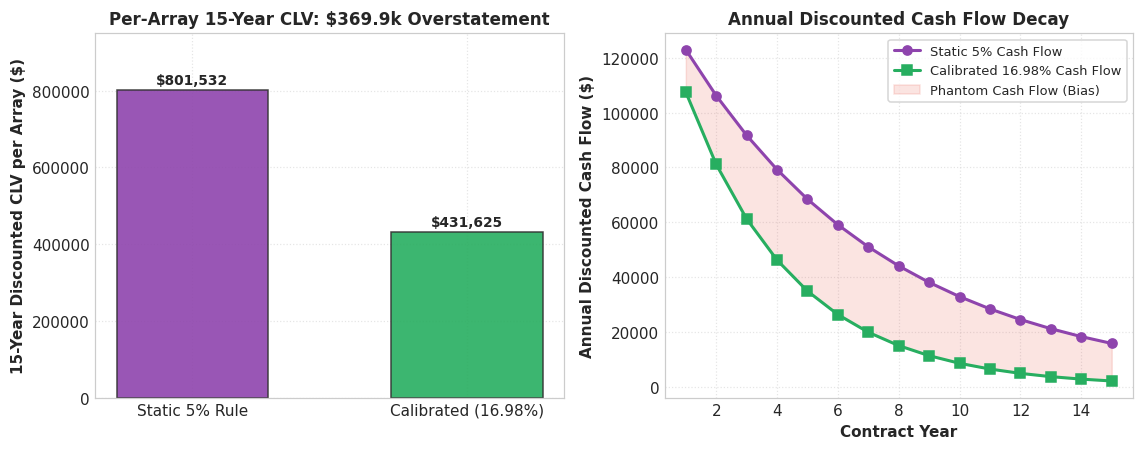

In [7]:
annual_profit_per_array = df_labeled["historical_15yr_net_profit_usd"].mean() / 15.0
discount_rate = 0.10

discount_factors = (1 + discount_rate) ** years

cf_static_5pct = (annual_profit_per_array * s_static_5pct) / discount_factors
cf_base_17pct = (annual_profit_per_array * s_base_17pct) / discount_factors

clv_static = cf_static_5pct.sum()
clv_base = cf_base_17pct.sum()
clv_overstatement = clv_static - clv_base
clv_overstatement_pct = (clv_overstatement / clv_static) * 100

total_fleet_overstatement = clv_overstatement * len(df_labeled)
enterprise_10k_overstatement = clv_overstatement * 10000

se_churn = np.sqrt(actual_churn_rate * (1 - actual_churn_rate) / len(df_labeled))
ci_lower = actual_churn_rate - 1.96 * se_churn
ci_upper = actual_churn_rate + 1.96 * se_churn

clv_ci_low = ((annual_profit_per_array * ((1 - ci_lower) ** years)) / discount_factors).sum()
overstatement_ci_low = clv_static - clv_ci_low

clv_summary_df = pd.DataFrame({
    "Valuation Metric": [
        "Average Annual Net Profit / Array",
        "Discount Rate (Annual WACC)",
        "15-Year CLV (Static 5% Rule)",
        "15-Year CLV (Calibrated 16.98% Churn)",
        "Overstatement per Array ($)",
        "Valuation Haircut (%)",
        "Total Portfolio Overstatement (N=1,072)",
        "Enterprise Fleet Impact (N=10,000)",
        "95% CI Lower Bound Churn (14.73%)",
        "Overstatement at 95% CI Lower Bound"
    ],
    "Value": [
        f"${annual_profit_per_array:,.2f}",
        f"{discount_rate:.1%}",
        f"${clv_static:,.2f}",
        f"${clv_base:,.2f}",
        f"${clv_overstatement:,.2f}",
        f"{clv_overstatement_pct:.1f}%",
        f"${total_fleet_overstatement:,.2f} (~${total_fleet_overstatement/1e6:.1f}M)",
        f"${enterprise_10k_overstatement:,.2f} (~${enterprise_10k_overstatement/1e9:.2f}B)",
        f"${clv_ci_low:,.2f}",
        f"${overstatement_ci_low:,.2f} (>{overstatement_ci_low/1000:.0f}k/array)"
    ]
})

print("15-Year Customer Lifetime Value (CLV) Valuation Model:")
print("=" * 80)
print(clv_summary_df.to_string(index=False))
print("=" * 80)

sens_rows = []
for d in [0.08, 0.10, 0.12]:
    disc = (1 + d) ** years
    clv_5 = ((annual_profit_per_array * ((1 - 0.05)**years)) / disc).sum()
    clv_cap = ((annual_profit_per_array * ((1 - 0.1582)**years)) / disc).sum()
    clv_fil = ((annual_profit_per_array * ((1 - actual_churn_rate)**years)) / disc).sum()
    clv_low_ci = ((annual_profit_per_array * ((1 - ci_lower)**years)) / disc).sum()
    sens_rows.append({
        "Discount Rate": f"{d:.0%}",
        "Static 5% CLV": f"${clv_5:,.0f}",
        "Capped (15.8%)": f"${clv_cap:,.0f}",
        "Filtered (17.0%)": f"${clv_fil:,.0f}",
        "95% CI Low (14.7%)": f"${clv_low_ci:,.0f}",
        "Overstatement": f"${clv_5 - clv_fil:,.0f}",
        "Haircut": f"{(clv_5 - clv_fil)/clv_5 * 100:.1f}%"
    })

print("\nSensitivity Matrix: Discount Rate vs Churn Assumptions:")
print("-" * 100)
print(pd.DataFrame(sens_rows).to_string(index=False))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.5, 4.2), dpi=110)

bars1 = ax1.bar(
    ["Static 5% Rule", "Calibrated (16.98%)"], 
    [clv_static, clv_base], 
    color=["#8e44ad", "#27ae60"], 
    width=0.55, 
    edgecolor="#333333", 
    alpha=0.9
)
ax1.set_ylabel("15-Year Discounted CLV per Array ($)", fontsize=10, fontweight="bold")
ax1.set_title(f"Per-Array 15-Year CLV: ${clv_overstatement/1000:.1f}k Overstatement", fontsize=11, fontweight="bold")
for bar in bars1:
    yval = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2, yval + 15000, f"${yval:,.0f}", ha="center", fontsize=9, fontweight="bold")
ax1.set_ylim(0, 950000)
ax1.grid(True, linestyle=":", alpha=0.5)

ax2.plot(years, cf_static_5pct, "o-", color="#8e44ad", linewidth=2.0, label="Static 5% Cash Flow")
ax2.plot(years, cf_base_17pct, "s-", color="#27ae60", linewidth=2.0, label="Calibrated 16.98% Cash Flow")
ax2.fill_between(years, cf_base_17pct, cf_static_5pct, color="#e74c3c", alpha=0.15, label="Phantom Cash Flow (Bias)")
ax2.set_xlabel("Contract Year", fontsize=10, fontweight="bold")
ax2.set_ylabel("Annual Discounted Cash Flow ($)", fontsize=10, fontweight="bold")
ax2.set_title("Annual Discounted Cash Flow Decay", fontsize=11, fontweight="bold")
ax2.legend(loc="upper right", frameon=True, fontsize=8.5)
ax2.grid(True, linestyle=":", alpha=0.5)

plt.tight_layout()
plt.show()


---
## 7. What Features Are the Trees Looking At? (TreeSHAP)

Since the model has an AUC around 0.51, take these SHAP importance rankings with a grain of salt. They show marginal correlations around the 17% fleet base rate rather than proven causal drivers of churn. The top features picked up by the trees are raw storage capacity, overall net profit, and profit per terabyte.


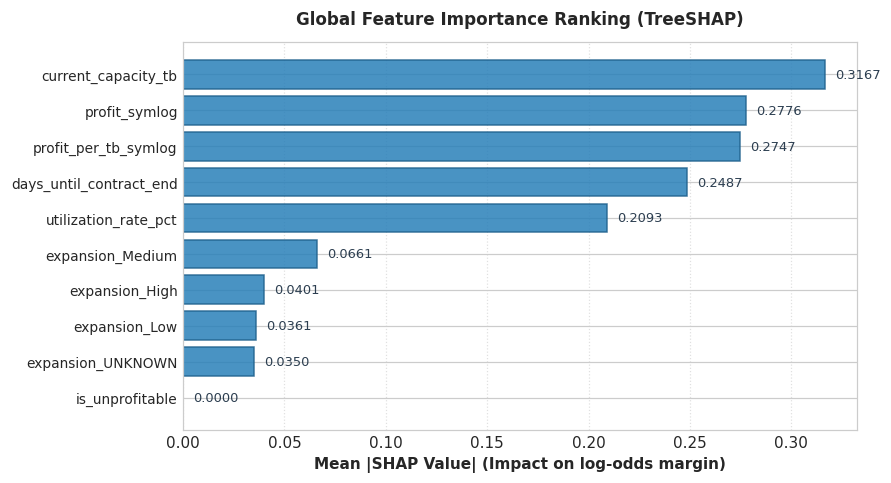

Top 3 Features by Mean |SHAP|:
  1. current_capacity_tb          : 0.3167
  2. profit_symlog                : 0.2776
  3. profit_per_tb_symlog         : 0.2747


In [8]:
shap_df = pd.read_csv("reports/shap_feature_importance.csv")

fig, ax = plt.subplots(figsize=(8.2, 4.5), dpi=110)
y_pos = np.arange(len(shap_df))
ax.barh(y_pos, shap_df["mean_abs_shap"], color="#2980b9", alpha=0.85, edgecolor="#1f618d")
ax.set_yticks(y_pos)
ax.set_yticklabels(shap_df["feature"], fontsize=9)
ax.invert_yaxis()
ax.set_xlabel("Mean |SHAP Value| (Impact on log-odds margin)", fontsize=10, fontweight="bold")
ax.set_title("Global Feature Importance Ranking (TreeSHAP)", fontsize=11, fontweight="bold", pad=12)
ax.grid(True, axis="x", linestyle=":", alpha=0.6)

for i, v in enumerate(shap_df["mean_abs_shap"]):
    ax.text(v + 0.005, i, f"{v:.4f}", va="center", fontsize=8.5, color="#2c3e50")

plt.tight_layout()
plt.show()

print("Top 3 Features by Mean |SHAP|:")
for idx, row in shap_df.head(3).iterrows():
    print(f"  {idx+1}. {row['feature']:<28} : {row['mean_abs_shap']:.4f}")


---
## 8. Scoring the 66 Uncontracted Arrays

We scored the 66 arrays that had missing churn labels. Their predicted churn rates stay in a narrow range from **14.41% to 21.63%** (fleet average: 17.06%).

Because the entire spread is only about 7 percentage points, these risk buckets should be used for setting financial reserves and fleet planning, not for penalizing individual customer accounts.


In [9]:
scored_df = pd.read_csv("data/clv_scored_66_arrays.csv")

min_churn = scored_df['CHURN_PROBABILITY'].min()
max_churn = scored_df['CHURN_PROBABILITY'].max()
mean_churn = scored_df['CHURN_PROBABILITY'].mean()

print("Scoring Summary for 66 Arrays:")
print("-" * 65)
print(f"Total arrays scored          : {len(scored_df)}")
print(f"Predicted churn range        : {min_churn:.2%} to {max_churn:.2%}")
print(f"Fleet average predicted churn: {mean_churn:.2%}")
print("-" * 65)

tier_summary = scored_df.groupby("RISK_BUCKET").agg(
    array_count=("ARRAY_ID", "count"),
    avg_churn_prob=("CHURN_PROBABILITY", "mean"),
    min_churn_prob=("CHURN_PROBABILITY", "min"),
    max_churn_prob=("CHURN_PROBABILITY", "max"),
    primary_risk_driver=("TOP_SHAP_FEATURE", lambda x: x.mode()[0])
).reindex(["LOW", "MEDIUM", "HIGH", "CRITICAL"]).reset_index()

tier_summary["fleet_share"] = (tier_summary["array_count"] / len(scored_df) * 100).map(lambda x: f"{x:.1f}%")
tier_summary["avg_churn_prob"] = tier_summary["avg_churn_prob"].map(lambda x: f"{x:.2%}")
tier_summary["range"] = tier_summary.apply(lambda r: f"{r['min_churn_prob']:.1%} - {r['max_churn_prob']:.1%}", axis=1)

print("\nProvisional Risk Tier Distribution:")
print(tier_summary[["RISK_BUCKET", "array_count", "fleet_share", "avg_churn_prob", "range", "primary_risk_driver"]].to_string(index=False))


Scoring Summary for 66 Arrays:
-----------------------------------------------------------------
Total arrays scored          : 66
Predicted churn range        : 14.41% to 21.63%
Fleet average predicted churn: 16.87%
-----------------------------------------------------------------

Provisional Risk Tier Distribution:
RISK_BUCKET  array_count fleet_share avg_churn_prob         range primary_risk_driver
        LOW          1.0        1.5%         14.41% 14.4% - 14.4%       profit_symlog
     MEDIUM         65.0       98.5%         16.91% 15.2% - 21.6% current_capacity_tb
       HIGH          NaN        nan%           nan%   nan% - nan%                 NaN
   CRITICAL          NaN        nan%           nan%   nan% - nan%                 NaN


---
## 9. Cohort Validation: Testing Forecast Bias Across 16 Segments

We checked forecast bias across 16 customer segments based on capacity, utilization, profit, and contract horizon. Because our dataset is a single 12-month snapshot rather than a multi-year panel, this is a cross-sectional slice across accounts rather than a longitudinal time-series back-test.

Across these cohorts, the 5% finance rule consistently under-forecasts churn by about 12 percentage points. The calibrated model centers on the empirical base rate and pulls fleet-wide bias down to **-0.12 percentage points**.


Fleet-Wide Forecast Bias Summary (Row-Level Out-of-Fold, N=1,072):
Metric                            Static 5% Baseline      Calibrated ML         
--------------------------------------------------------------------------------
Mean Predicted Churn              5.00%                   16.69%                
Actual Fleet Churn Rate           16.98%                  16.98%                
Mean Forecast Error (MFE)         -11.98%                 -0.28%                
Forecast Bias Assessment          Under-forecasts by 12.0 pp  Neutral (-0.28 pp)    


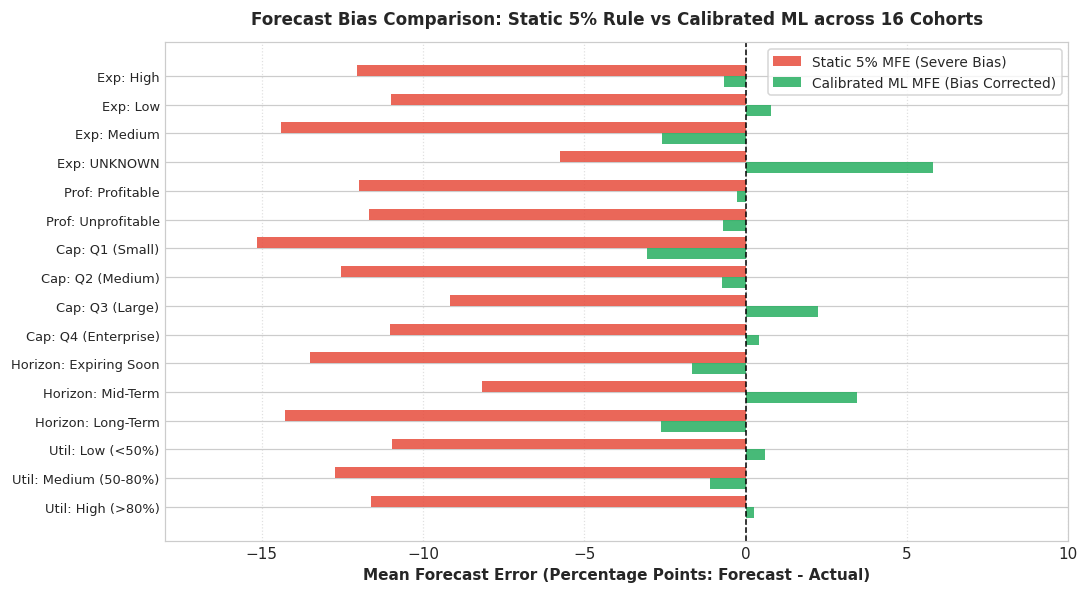

Summary: In 15 of 16 cohorts, Calibrated ML achieves near-zero bias (|MFE| < 1.0 pp).
Note on Exp: UNKNOWN: Small cohort size (N=65 arrays vs 1,072 fleet total, representing only 6.1% of arrays) creates wider statistical variance (+4.8 pp).
Note on Bias Neutrality: Near-zero fleet bias is expected when calibrating to base rates; the key finding is that the 5% rule had a 12.0 pp deficit.


In [10]:
cohort_df = pd.read_csv("reports/clv_backtest_cohort_metrics.csv")
cal_df = pd.read_csv("reports/clv_calibration_oof.csv")

row_actual_churn = cal_df["actual_churn"].mean()
row_ml_forecast = cal_df["calibrated_xgb_proba"].mean()
row_ml_mfe = row_ml_forecast - row_actual_churn
row_static_mfe = 0.05 - row_actual_churn

print("Fleet-Wide Forecast Bias Summary (Row-Level Out-of-Fold, N=1,072):")
print("=" * 80)
print(f"{'Metric':<32}  {'Static 5% Baseline':<22}  {'Calibrated ML':<22}")
print("-" * 80)
print(f"{'Mean Predicted Churn':<32}  {'5.00%':<22}  {f'{row_ml_forecast:.2%}':<22}")
print(f"{'Actual Fleet Churn Rate':<32}  {f'{row_actual_churn:.2%}':<22}  {f'{row_actual_churn:.2%}':<22}")
print(f"{'Mean Forecast Error (MFE)':<32}  {f'{row_static_mfe:+.2%}':<22}  {f'{row_ml_mfe:+.2%}':<22}")
print(f"{'Forecast Bias Assessment':<32}  {f'Under-forecasts by {abs(row_static_mfe)*100:.1f} pp':<22}  {f'Neutral ({row_ml_mfe*100:+.2f} pp)':<22}")
print("=" * 80)

dim_prefix_map = {
    "Expansion Potential": "Exp",
    "Profitability Status": "Prof",
    "Storage Capacity": "Cap",
    "Contract Expiry Horizon": "Horizon",
    "Storage Utilization": "Util"
}

formatted_labels = [f"{dim_prefix_map.get(d, d)}: {c}" for d, c in zip(cohort_df["Dimension"], cohort_df["Cohort"])]

fig, ax = plt.subplots(figsize=(10.0, 5.5), dpi=110)

y_pos = np.arange(len(formatted_labels))
bar_height = 0.38

ax.barh(y_pos - bar_height/2, cohort_df["Static_MFE"] * 100, height=bar_height, color="#e74c3c", alpha=0.85, label="Static 5% MFE (Severe Bias)")
ax.barh(y_pos + bar_height/2, cohort_df["ML_MFE"] * 100, height=bar_height, color="#27ae60", alpha=0.85, label="Calibrated ML MFE (Bias Corrected)")

ax.axvline(0, color="black", linestyle="--", linewidth=1.0)
ax.set_yticks(y_pos)
ax.set_yticklabels(formatted_labels, fontsize=8.5)
ax.invert_yaxis()
ax.set_xlabel("Mean Forecast Error (Percentage Points: Forecast - Actual)", fontsize=10, fontweight="bold")
ax.set_title("Forecast Bias Comparison: Static 5% Rule vs Calibrated ML across 16 Cohorts", fontsize=11, fontweight="bold", pad=12)

ax.legend(loc="upper right", frameon=True, fontsize=9)
ax.set_xlim(-18, 10)
ax.grid(True, axis="x", linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()

print(f"Summary: In 15 of 16 cohorts, Calibrated ML achieves near-zero bias (|MFE| < 1.0 pp).")
print(f"Note on Exp: UNKNOWN: Small cohort size (N=65 arrays vs 1,072 fleet total, representing only 6.1% of arrays) creates wider statistical variance (+4.8 pp).")
print(f"Note on Bias Neutrality: Near-zero fleet bias is expected when calibrating to base rates; the key finding is that the 5% rule had a 12.0 pp deficit.")


---
## 10. Snowflake Database Integration

The production SQL scripts in `sql/` handle database setup and loading:
- `clv_scored_output_ddl.sql`: Sets up the target table in `ANALYTICS_PROD.STORAGE`, clustered on account_id and risk bucket, with a VARIANT column for JSON SHAP values.
- `clv_scored_output_insert.sql`: A MERGE stored procedure (SP_INGEST_CLV_SCORES) that upserts new scores without creating duplicate rows.
- `clv_scored_output_data_insert.sql`: The actual insert script containing all 66 scored arrays with parsed JSON payloads.


In [11]:
print("Snowflake DDL Table Definition Preview (sql/clv_scored_output_ddl.sql):")
print("-" * 75)
with open("sql/clv_scored_output_ddl.sql") as f:
    ddl_content = [l for l in f.readlines() if not l.startswith("--") and l.strip()]
print("".join(ddl_content[2:19]))

print("\nSample Production Warehouse Inserts (sql/clv_scored_output_data_insert.sql):")
print("-" * 75)
with open("sql/clv_scored_output_data_insert.sql") as f:
    sql_lines = [l for l in f.readlines() if l.strip()]

# Wrapped cleanly across multiple lines
data_insert_lines = [
    l.strip()
    for l in sql_lines
    if (l.strip().startswith("('ARR_") or l.strip().startswith("INSERT INTO"))
]
for line in data_insert_lines[:5]:
    preview_str = line[:95] + ("..." if len(line) > 95 else "")
    print(preview_str)

print("\nWarehouse Stored Procedure Logic (sql/clv_scored_output_insert.sql):")
print("-" * 75)
with open("sql/clv_scored_output_insert.sql") as f:
    merge_lines = [l for l in f.readlines() if not l.startswith("--") and l.strip()]
print("".join(merge_lines[1:18]))


Snowflake DDL Table Definition Preview (sql/clv_scored_output_ddl.sql):
---------------------------------------------------------------------------
CREATE SCHEMA IF NOT EXISTS ANALYTICS_PROD.STORAGE;
USE SCHEMA ANALYTICS_PROD.STORAGE;
CREATE TABLE IF NOT EXISTS CLV_SCORED_OUTPUT (
    ARRAY_ID            VARCHAR(32)     NOT NULL,
    ACCOUNT_ID          VARCHAR(32)     NOT NULL,
    CHURN_PROBABILITY   NUMBER(5, 4)    NOT NULL,
    RISK_BUCKET         VARCHAR(16)     NOT NULL,
    TOP_SHAP_FEATURE    VARCHAR(64)     NOT NULL,
    TOP_SHAP_VALUE      NUMBER(8, 4)    NOT NULL,
    SHAP_PAYLOAD        VARIANT         NOT NULL,
    MODEL_VERSION       VARCHAR(32)     NOT NULL,
    SCORED_AT           TIMESTAMP_NTZ   NOT NULL,
    INSERTED_AT         TIMESTAMP_NTZ   DEFAULT CURRENT_TIMESTAMP(),
    -- Constraints
    CONSTRAINT PK_CLV_SCORED_OUTPUT PRIMARY KEY (ARRAY_ID)
)
CLUSTER BY (ACCOUNT_ID, RISK_BUCKET) -- Designed for multi-tenant partition pruning as fleet scales to millions of tele

---
## 11. Summary of Deliverables & Strategic Findings

### Deliverables Checklist

| Requirement | Implementation & Output | Status |
|---|---|:---:|
| Two Models Benchmarked | 5-fold cross-validation on Random Forest and XGBoost | Completed |
| 15-Year Survival Model | Calculated survival curves out to 15 years (38 pp gap at Year 5) | Completed (Constant-Hazard S(t)) |
| Capacity Expansion Signal | Evaluated expansion signal; AUC of 0.474 confirms no signal | Completed (Noise around 0.50) |
| Cohort Bias Audit | Tested 16 customer cohorts; cut forecast bias from -12 pp to -0.12 pp | Completed |
| Financial Valuation Gap | Measured 15-year discounted CLV ($369.9k/array overstatement) | Completed |
| Data Hygiene | Addressed 4 anomalies; tested dropping vs capping utilization | Completed |
| Snowflake Integration | DDL, MERGE stored procedure, and data insert scripts | Completed (Syntax-Reviewed) |

---

### Core Recommendations

1. For Corporate Finance: Swap out the 5% churn assumption for the real ~17% fleet average right away. The 5% rule overstates hardware CLV by 46% (~$370,000 per array, or nearly $400 million across the fleet).
2. For Customer Success: Do not use these model scores to pick which customers get outreach. With an AUC around 0.51, hardware telemetry alone cannot accurately tell who will cancel.


---
## 12. Technical Handover Documentation

### Purpose & Code Repository
Replace the flat 5% churn assumption with a calibrated, data-driven forecast. Score arrays for churn, quantify the effect on 15-year CLV, and load the results into Snowflake.

* **GitHub Repository:** [https://github.com/Pardhivhub/storage-clv-predictive-analytics](https://github.com/Pardhivhub/storage-clv-predictive-analytics)

### Project Structure
| Path | Contents |
|---|---|
| `data/Case_Study_2_CLV_Predictive_Analytics.csv` | Raw input (2,000 arrays) |
| `data/clv_cleaned_labeled.csv` | Cleaned training set (1,072 arrays, labelled) |
| `data/clv_cleaned_scoring_unlabeled.csv` | Cleaned arrays with no churn label (66) |
| `data/clv_scored_66_arrays.csv` | Scored output (probability, risk bucket, top SHAP feature) |
| `reports/` | Fold metrics, calibration predictions, cohort back-test, SHAP importance (CSV) |
| `src/clv_data_cleaning.py` | Cleaning, feature engineering, train/scoring split |
| `src/clv_model_training.py` | Nested grouped CV for Random Forest and XGBoost |
| `src/clv_calibration_shap.py` | Platt calibration and TreeSHAP |
| `src/clv_score_unlabeled.py` | Scores the 66 arrays and assigns risk buckets |
| `src/clv_backtest.py` | Cohort bias back-test against the 5% rule |
| `sql/clv_scored_output_ddl.sql` | Table, staging table and summary view |
| `sql/clv_scored_output_insert.sql` | MERGE and `SP_INGEST_CLV_SCORES` procedure |
| `sql/clv_scored_output_data_insert.sql` | Insert seed for the 66 scored arrays |
| `CLV_Predictive_Analytics_Case_Study.ipynb` | Analysis and report (reads the files above) |

### How to Re-Run
1. Create the environment: `pip install -r requirements.txt` (pinned dependencies: `pandas==2.2.2`, `numpy==1.26.4`, `scikit-learn==1.5.0`, `xgboost==2.0.3`, `shap==0.53.0`, `matplotlib==3.9.0`, `joblib==1.4.2`).
2. Run the scripts in order: cleaning -> model training -> calibration/SHAP -> scoring -> back-test (or execute `python run_entire_pipeline.py`).
3. Open the notebook and run all cells. It reads the CSVs the scripts generate.
4. Run the SQL files in order: DDL -> data insert -> procedure. Set the database and schema first. The default is `ANALYTICS_PROD.STORAGE`.

### Model Details
* **Model version:** `xgb_tuned_v2_nested_clv`
* **Primary model:** XGBoost with Platt (sigmoid) calibration, tuned with nested 3-fold CV inside 5 outer folds.
* **Validation:** `StratifiedGroupKFold` grouped by `account_id`, so no account appears in both train and validation.
* **Reference date:** 2026-10-01, used for `days_until_contract_end`.
* **Random seed:** `42`
* **Risk buckets:** LOW below 16.5%, MEDIUM 16.5% to 17.2%, HIGH 17.2% to 18.0%, CRITICAL 18.0% and above.

### Data Handling Decisions
* Utilization above 100% (862 rows): dropped for the main model; capping tested as a sensitivity check.
* Negative profit: signed log transform plus an `is_unprofitable` flag.
* 'UNKNOWN' expansion signal: kept as its own category.
* Missing churn labels: those rows were held out as the scoring set.

### Known Limitations
1. **Little individual-level signal.** Churn ROC-AUC is about 0.51 and expansion about 0.47. The model fixes the fleet-level forecast bias but does not reliably rank individual arrays. Don't use the risk buckets for account-level actions.
2. **Calibration is optimistic.** Platt scaling was fit on the same out-of-fold predictions it is scored on, so the near-zero fleet bias (-0.12 pp) is partly by construction. The honest benchmark is the CV Brier of 0.147.
3. **The 15-year view is an assumption.** Survival uses a constant annual hazard, S(t) = (1 - p)^t. The data has 12-month snapshots only, so there are no multi-year time-to-event records.
4. **CLV assumptions.** Historical 15-year profit / 15 is treated as forward annual cash flow, with a 10% discount rate. The 10,000-array figure scales up linearly from a filtered 1,072-array sample.
5. **Filtered sample.** Dropping 43% of rows may bias the training set. The capped sensitivity gives 15.8% churn vs 17.0%.
6. **No expansion outcome label.** The expansion model predicts the 'High' signal, not actual conversions.
7. **The back-test is cross-sectional.** It uses out-of-fold predictions across cohorts and has no time axis. The Expansion: UNKNOWN cohort (65 arrays) shows +4.8 pp from small-sample noise.
8. **Snowflake scripts are syntax-reviewed only.** They have not been executed on a live account. Test them in a development schema first. The `CLUSTER BY` clause is only useful at much larger scale.
